## importing labrabries


In [95]:
import numpy as np
import pandas as pd

In [96]:
sale_df = pd.read_csv(r"C:\Users\ACER\OneDrive\Desktop\Retail_sale_analysis\data\bm_sales.csv")
product_df = pd.read_csv(r"C:\Users\ACER\OneDrive\Desktop\Retail_sale_analysis\data\bm_skus.csv")
stores_df = pd.read_csv(r"C:\Users\ACER\OneDrive\Desktop\Retail_sale_analysis\data\bm_stores.csv")

In [97]:
sale_df.head()

,date,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0


In [98]:
product_df.head()

,sku_id,sku_name,category,subcategory,unit_price,cost_price,brand
0,1001,Electronics_Chargers_1001,Electronics,Chargers,164.56,103.44,Budget
1,1002,Dairy_Cream_1002,Dairy,Cream,13.73,8.96,Local
2,1003,Household_Cleaning Supplies_1003,Household,Cleaning Supplies,12.00,7.47,BlueMart
3,1004,Beverages_Juices_1004,Beverages,Juices,24.82,17.58,International
4,1005,Household_Paper Products_1005,Household,Paper Products,17.70,13.68,Budget


In [99]:
stores_df.head()

,store_id,store_name,city,store_type,opening_date
0,9,BlueMart Store 09,Abu Dhabi,Mall,2017-01-01 00:00:00.000000000
1,10,BlueMart Store 10,Abu Dhabi,Mall,2017-01-31 00:00:00.000000000
2,11,BlueMart Store 11,Dubai,Mall,2017-03-02 00:00:00.000000000
3,12,BlueMart Store 12,Sharjah,Mall,2017-04-01 00:00:00.000000000
4,13,BlueMart Store 13,Sharjah,Community,2017-05-01 00:00:00.000000000


## Data Inspection

In [100]:
# sale dataset inpection.

sale_df.sample(5)

,date,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct
136842,2022-01-08,23,1189,2320.0,4,58.49,233.96,Store,25.0
125019,2021-12-06,34,1006,NaN,1,12.62,12.62,Store,0.0
35406,2021-03-20,1,1180,1781.0,2,8.40,16.80,Store,0.0
113413,2021-10-28,45,1102,1009.0,1,21.54,21.54,Store,0.0
349287,2023-08-04,38,1141,3295.0,6,6.76,40.56,Store,20.0


In [101]:
sale_df.shape

(641843, 9)

In [102]:
sale_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 641843 entries, 0 to 641842
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   date          641843 non-null  object 
 1   store_id      641843 non-null  int64  
 2   sku_id        641843 non-null  int64  
 3   customer_id   482022 non-null  float64
 4   quantity      641843 non-null  int64  
 5   unit_price    641843 non-null  float64
 6   total_value   641843 non-null  float64
 7   channel       641843 non-null  object 
 8   discount_pct  641843 non-null  float64
dtypes: float64(4), int64(3), object(2)
memory usage: 44.1+ MB


In [103]:
sale_df["discount_pct"].sample(10)

522317     0.0
97540     10.0
406340    15.0
533298     0.0
213601     0.0
70989      0.0
65339      0.0
250404     0.0
298745     0.0
634602     0.0
Name: discount_pct, dtype: float64

In [104]:
sale_df.isna().sum()

date                 0
store_id             0
sku_id               0
customer_id     159821
quantity             0
unit_price           0
total_value          0
channel              0
discount_pct         0
dtype: int64

In [91]:
import matplotlib.pyplot as plt

In [ ]:
customer_id_null = sale_df["customer_id"].isna().sum()
customer_id_value = sale_df["customer_id"].count()
customer_id_total = customer_id_null + customer_id_value

<BarContainer object of 3 artists>

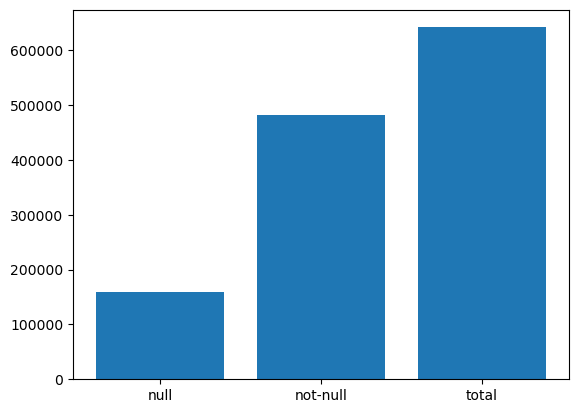

In [92]:
label = ["null" , "not-null" , "total"]
count = [customer_id_null , customer_id_value , customer_id_total ]

plt.bar(label , count)

In [93]:
for i in count:
    per = (i / customer_id_total) * 100
    print(round(per))

25
75
100


In [106]:
sale_df.describe()

,store_id,sku_id,customer_id,quantity,unit_price,total_value,discount_pct
count,641843.000000,641843.000000,482022.000000,641843.000000,641843.000000,641843.000000,641843.000000
mean,25.491081,1100.547835,2504.986828,2.613120,44.109242,114.069845,5.411316
std,14.437269,57.684158,1442.340254,1.481563,48.984342,157.206354,8.664765
min,1.000000,1001.000000,1.000000,1.000000,1.700000,1.700000,0.000000
25%,13.000000,1051.000000,1260.000000,1.000000,14.280000,27.320000,0.000000
50%,25.000000,1101.000000,2507.000000,2.000000,24.330000,57.660000,0.000000
75%,38.000000,1150.000000,3752.000000,4.000000,49.570000,129.550000,10.000000
max,50.000000,1200.000000,5000.000000,6.000000,245.380000,1472.280000,35.000000


In [94]:
# col which have to chnage col type in sales_df.

# date     (obj to date) must

# customer_id (float to int) optinal
# discount_pct  (float to int ) optinal.

# we 75% of customer_id is null.

In [108]:
# product dataset inpection.

product_df.head()

,sku_id,sku_name,category,subcategory,unit_price,cost_price,brand
0,1001,Electronics_Chargers_1001,Electronics,Chargers,164.56,103.44,Budget
1,1002,Dairy_Cream_1002,Dairy,Cream,13.73,8.96,Local
2,1003,Household_Cleaning Supplies_1003,Household,Cleaning Supplies,12.00,7.47,BlueMart
3,1004,Beverages_Juices_1004,Beverages,Juices,24.82,17.58,International
4,1005,Household_Paper Products_1005,Household,Paper Products,17.70,13.68,Budget


In [110]:
product_df.shape

(200, 7)

In [113]:
product_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   sku_id       200 non-null    int64  
 1   sku_name     200 non-null    object 
 2   category     200 non-null    object 
 3   subcategory  200 non-null    object 
 4   unit_price   200 non-null    float64
 5   cost_price   200 non-null    float64
 6   brand        200 non-null    object 
dtypes: float64(2), int64(1), object(4)
memory usage: 11.1+ KB


In [114]:
product_df.isna().sum()

sku_id         0
sku_name       0
category       0
subcategory    0
unit_price     0
cost_price     0
brand          0
dtype: int64

In [116]:
product_df.describe()

,sku_id,unit_price,cost_price
count,200.000000,200.000000,200.000000
mean,1100.500000,46.682300,31.060100
std,57.879185,51.590508,34.435869
min,1001.000000,2.610000,1.680000
25%,1050.750000,15.242500,10.065000
50%,1100.500000,25.910000,17.115000
75%,1150.250000,51.270000,34.322500
max,1200.000000,245.380000,187.670000


In [117]:
# all good neet and clean dataset

In [118]:
# stores dataset inpection.
stores_df.head()

,store_id,store_name,city,store_type,opening_date
0,9,BlueMart Store 09,Abu Dhabi,Mall,2017-01-01 00:00:00.000000000
1,10,BlueMart Store 10,Abu Dhabi,Mall,2017-01-31 00:00:00.000000000
2,11,BlueMart Store 11,Dubai,Mall,2017-03-02 00:00:00.000000000
3,12,BlueMart Store 12,Sharjah,Mall,2017-04-01 00:00:00.000000000
4,13,BlueMart Store 13,Sharjah,Community,2017-05-01 00:00:00.000000000


In [119]:
stores_df.shape

(50, 5)

In [120]:
stores_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   store_id      50 non-null     int64 
 1   store_name    50 non-null     object
 2   city          50 non-null     object
 3   store_type    50 non-null     object
 4   opening_date  50 non-null     object
dtypes: int64(1), object(4)
memory usage: 2.1+ KB


In [121]:
stores_df.describe()

,store_id
count,50.00000
mean,25.50000
std,14.57738
min,1.00000
25%,13.25000
50%,25.50000
75%,37.75000
max,50.00000


In [ ]:
# opening date is obj change to date_time.
